In [6]:
import os  # for accessing files
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import cv2  # for image prosessing
from PIL import Image #PIL -> pillow libary used for image processing libraries
from sklearn.model_selection import train_test_split

In [7]:
tumor=os.listdir('C:/Users/Khadeejas/Desktop/Project Keltron/Brain Tumor Data Set/Brain Tumor') # create list contain files with mask
print(tumor[:5])  # print the first five elements
print(tumor[-5:]) # print the last five elements of the list

['Cancer (1).jpg', 'Cancer (10).jpg', 'Cancer (100).jpg', 'Cancer (1000).jpg', 'Cancer (1001).jpg']
['Cancer (995).jpg', 'Cancer (996).jpg', 'Cancer (997).jpg', 'Cancer (998).JPG', 'Cancer (999).jpg']


In [8]:
healthy=os.listdir('C:/Users/Khadeejas/Desktop/Project Keltron/Brain Tumor Data Set/Healthy') # create list contain files without mask
print(healthy[:5])  # print the first five elements
print(healthy[-5:])  # print the last five elements of the list

['Not Cancer  (1).jpeg', 'Not Cancer  (1).jpg', 'Not Cancer  (10).jpg', 'Not Cancer  (100).jpg', 'Not Cancer  (1000).jpg']
['Not Cancer  (995).jpg', 'Not Cancer  (996).jpg', 'Not Cancer  (997).jpg', 'Not Cancer  (998).jpg', 'Not Cancer  (999).jpg']


In [9]:
print('Number of tumor images:',len(tumor))
print('number of healthy images:', len(healthy))

Number of tumor images: 2426
number of healthy images: 2086


In [10]:
#creating the labels
tumor_labels = [0]*len(tumor)
healthy_labels = [1]*len(healthy)

In [11]:
print(tumor_labels[:5])
print(healthy_labels[:5])

[0, 0, 0, 0, 0]
[1, 1, 1, 1, 1]


In [12]:
print(len(tumor_labels))
print(len(healthy_labels))

2426
2086


In [13]:
labels = tumor_labels + healthy_labels # adding the to list

print(len(labels))
print(labels[0:5])
print(labels[-5:])

4512
[0, 0, 0, 0, 0]
[1, 1, 1, 1, 1]


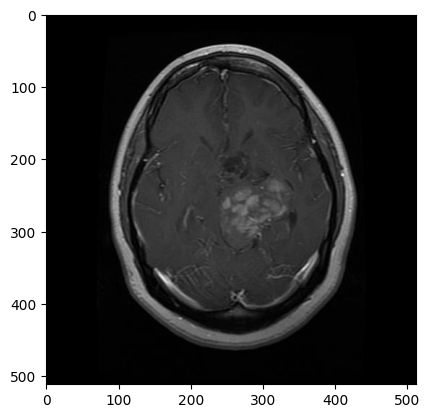

In [14]:
# dispolaying tumor image
img=mpimg.imread('C:/Users/Khadeejas/Desktop/Project Keltron/Brain Tumor Data Set/Brain Tumor/Cancer (1).jpg') # read the image into numpy array
imgplot = plt.imshow(img)
plt.show()

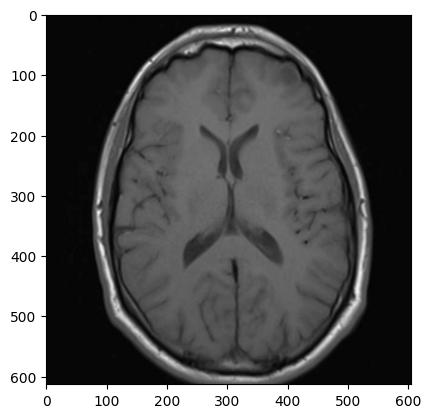

In [15]:
#displaying healthy image
img = mpimg.imread('C:/Users/Khadeejas/Desktop/Project Keltron/Brain Tumor Data Set/Healthy/Not Cancer  (4).jpg')
imgplot = plt.imshow(img)
plt.show()

In [16]:
def convert_images_to_numpy(image_dir, target_size=(128, 128)):
    data = []
    for img_file in os.listdir(image_dir):
        img_path = os.path.join(image_dir, img_file)
        if os.path.isfile(img_path):
            with Image.open(img_path) as image:
                image = image.resize(target_size)  # resize image
                image = image.convert('RGB')       # convert to RGB VV
                image_array = np.array(image)      # convert to numpy array
                data.append(image_array)
    return data

# Paths to the directories containing images
tumor_path = 'C:/Users/Khadeejas/Desktop/Project Keltron/Brain Tumor Data Set/Brain Tumor'
healthy_path = 'C:/Users/Khadeejas/Desktop/Project Keltron/Brain Tumor Data Set/Healthy'

# Convert images in both directories to numpy arrays
data_tumor = convert_images_to_numpy(tumor_path)
data_healthy = convert_images_to_numpy(healthy_path)

# Combine the data from both directories
data = data_tumor + data_healthy

In [17]:
data[0]

array([[[0, 0, 0],
        [0, 0, 0],
        [0, 0, 0],
        ...,
        [0, 0, 0],
        [0, 0, 0],
        [0, 0, 0]],

       [[0, 0, 0],
        [0, 0, 0],
        [0, 0, 0],
        ...,
        [0, 0, 0],
        [0, 0, 0],
        [0, 0, 0]],

       [[0, 0, 0],
        [0, 0, 0],
        [0, 0, 0],
        ...,
        [0, 0, 0],
        [0, 0, 0],
        [0, 0, 0]],

       ...,

       [[0, 0, 0],
        [0, 0, 0],
        [0, 0, 0],
        ...,
        [0, 0, 0],
        [0, 0, 0],
        [0, 0, 0]],

       [[0, 0, 0],
        [0, 0, 0],
        [0, 0, 0],
        ...,
        [0, 0, 0],
        [0, 0, 0],
        [0, 0, 0]],

       [[0, 0, 0],
        [0, 0, 0],
        [0, 0, 0],
        ...,
        [0, 0, 0],
        [0, 0, 0],
        [0, 0, 0]]], dtype=uint8)

In [18]:
type(data[0])

numpy.ndarray

In [19]:
data[0].shape

(128, 128, 3)

In [20]:
len(data)

4512

In [21]:
len(labels)

4512

In [22]:
#converting image list and label list to numpy arrays

X = np.array(data)
Y = np.array(labels)

In [23]:
type(X)

numpy.ndarray

In [24]:
type(Y)

numpy.ndarray

In [25]:
Y

array([0, 0, 0, ..., 1, 1, 1])

In [26]:
x_train, x_test, y_train, y_test = train_test_split(X,Y,test_size=0.2, random_state=2)

In [27]:
print(X.shape, x_train.shape, x_test.shape)

(4512, 128, 128, 3) (3609, 128, 128, 3) (903, 128, 128, 3)


In [28]:
#scaling the data

x_train_scaled =  x_train/255   #to change the value from 0 to 1


x_test_scaled = x_test/255

In [29]:
x_train_scaled[0]

array([[[0.        , 0.        , 0.        ],
        [0.        , 0.        , 0.        ],
        [0.        , 0.        , 0.        ],
        ...,
        [0.        , 0.        , 0.        ],
        [0.        , 0.        , 0.        ],
        [0.        , 0.        , 0.        ]],

       [[0.        , 0.        , 0.        ],
        [0.        , 0.        , 0.        ],
        [0.        , 0.        , 0.        ],
        ...,
        [0.00784314, 0.00784314, 0.00784314],
        [0.00784314, 0.00784314, 0.00784314],
        [0.00784314, 0.00784314, 0.00784314]],

       [[0.        , 0.        , 0.        ],
        [0.        , 0.        , 0.        ],
        [0.        , 0.        , 0.        ],
        ...,
        [0.00784314, 0.00784314, 0.00784314],
        [0.01176471, 0.01176471, 0.01176471],
        [0.01176471, 0.01176471, 0.01176471]],

       ...,

       [[0.00392157, 0.00392157, 0.00392157],
        [0.00392157, 0.00392157, 0.00392157],
        [0.00784314, 0

In [30]:
import tensorflow as tf
from tensorflow import keras

In [31]:
num_of_classes = 2

# Convert integer class labels to one-hot encoded vectors, Y_train  should contains integer class labels

Y_train_one_hot = tf.keras.utils.to_categorical(y_train, num_of_classes)


Y_test_one_hot = tf.keras.utils.to_categorical(y_test, num_of_classes)

In [32]:
Y_train_one_hot

array([[1., 0.],
       [1., 0.],
       [0., 1.],
       ...,
       [0., 1.],
       [0., 1.],
       [0., 1.]])

In [33]:
input_shape = (128,128,3)
# Define and compile your model
model = keras.Sequential([
    keras.layers.Conv2D(32, (3, 3), activation='relu', input_shape=input_shape),
    keras.layers.BatchNormalization(),
    keras.layers.MaxPooling2D(pool_size=(2, 2)),

    keras.layers.Conv2D(64, (3, 3), activation='relu'),
    keras.layers.BatchNormalization(),
    keras.layers.MaxPooling2D(pool_size=(2, 2)),

    keras.layers.Conv2D(128, (3, 3), activation='relu'),
    keras.layers.BatchNormalization(),
    keras.layers.MaxPooling2D(pool_size=(2, 2)),

    keras.layers.Flatten(),

    keras.layers.Dense(128, activation='relu'),
    keras.layers.Dropout(0.5),

    keras.layers.Dense(num_of_classes, activation='softmax')
])

c:\Users\Khadeejas\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [34]:
#compile the nerual network
model.compile(optimizer='adam',
              loss='categorical_crossentropy',
              metrics=['accuracy'])

In [35]:
history = model.fit(x_train_scaled, Y_train_one_hot, validation_split=0.1, epochs=10)

Epoch 1/10
102/102 ━━━━━━━━━━━━━━━━━━━━ 72s 661ms/step - accuracy: 0.6617 - loss: 3.3653 - val_accuracy: 0.4737 - val_loss: 3.6825
Epoch 2/10
102/102 ━━━━━━━━━━━━━━━━━━━━ 68s 670ms/step - accuracy: 0.7891 - loss: 0.4256 - val_accuracy: 0.4737 - val_loss: 2.1542
Epoch 3/10
102/102 ━━━━━━━━━━━━━━━━━━━━ 65s 638ms/step - accuracy: 0.8198 - loss: 0.3895 - val_accuracy: 0.7064 - val_loss: 0.6929
Epoch 4/10
102/102 ━━━━━━━━━━━━━━━━━━━━ 64s 631ms/step - accuracy: 0.8376 - loss: 0.3226 - val_accuracy: 0.8089 - val_loss: 0.3764
Epoch 5/10
102/102 ━━━━━━━━━━━━━━━━━━━━ 82s 631ms/step - accuracy: 0.8685 - loss: 0.2864 - val_accuracy: 0.8532 - val_loss: 0.3213
Epoch 6/10
102/102 ━━━━━━━━━━━━━━━━━━━━ 64s 628ms/step - accuracy: 0.8957 - loss: 0.2382 - val_accuracy: 0.9197 - val_loss: 0.2139
Epoch 7/10
102/102 ━━━━━━━━━━━━━━━━━━━━ 65s 638ms/step - accuracy: 0.9289 - loss: 0.1599 - val_accuracy: 0.9003 - val_loss: 0.2687
Epoch 8/10
102/102 ━━━━━━━━━━━━━━━━━━━━ 81s 627ms/step - accuracy: 0.9329 - loss: 0

In [36]:
loss,accuracy = model.evaluate(x_test_scaled,Y_test_one_hot)
print('Test Accuracy= ', accuracy)

29/29 ━━━━━━━━━━━━━━━━━━━━ 4s 124ms/step - accuracy: 0.9458 - loss: 0.1237
Test Accuracy=  0.9523809552192688


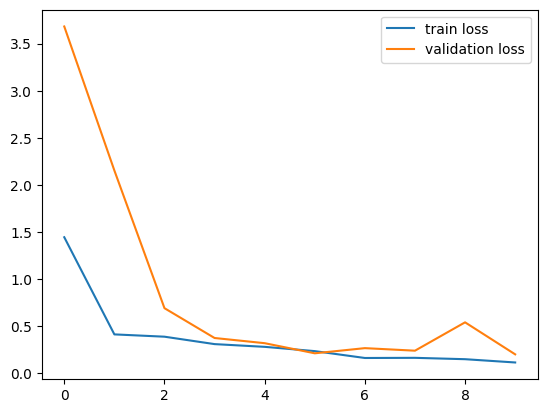

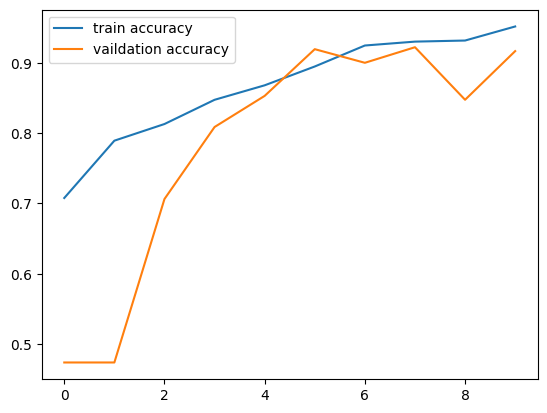

In [37]:
h = history

#plot the loss value
plt.plot(h.history['loss'], label='train loss')
plt.plot(h.history['val_loss'], label='validation loss')
plt.legend()
plt.show()

#plot the accuracy value
plt.plot(h.history['accuracy'], label='train accuracy')
plt.plot(h.history['val_accuracy'], label='vaildation accuracy')
plt.legend()
plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 140ms/step
[[9.9999893e-01 1.0572179e-06]]
0
The photo is of the brain with tumor


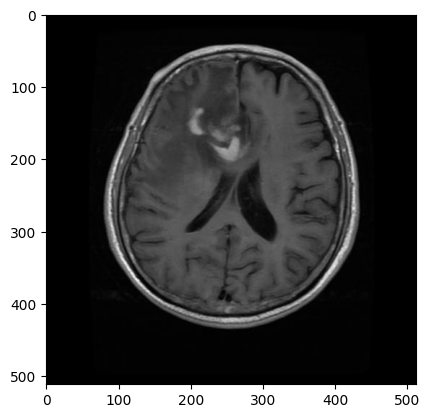

In [38]:
# @title Default title text
input_image_path = input('path of the image to be pedicted: ')
input_image = cv2.imread(input_image_path)

plt.imshow(input_image)

input_image_resized = cv2.resize(input_image, (128,128))

input_image_scaled = input_image_resized/255

input_image_reshaped = np.reshape(input_image_scaled,[1,128,128,3])

input_prediction=model.predict(input_image_reshaped)

print(input_prediction)

input_pred_label = np.argmax(input_prediction)

print(input_pred_label)

if input_pred_label == 0:
  print('The photo is of the brain with tumor')

elif input_pred_label == 1:
  print('The photo is of a healthy brain')